In [30]:
from src.data.loader import load_csv
import pandas as pd
"""
target_vwap_up — средневзвешенная по объёму цена (VWAP) aFRR в направлении вверх (UP) на венгерском рынке, €/МВт·ч. Если в данный час активации не было, значение равно 0.
Признаки (это прогнозы на сутки вперёд, известные заранее):
consumption — потребление электроэнергии, МВт·ч/ч
wind — выработка ветровых станций, МВт·ч/ч
solar — выработка солнечных станций, МВт·ч/ч
nuclear — выработка АЭС, МВт·ч/ч
temperature — температура, °C
exchange_net_export — чистый экспорт (перетоки с соседними странами), МВт·ч/ч
carbon_intensity_production — углеродоёмкость производства, кгCO₂-экв/МВт·ч

"""

DATA_PATH = "../data/raw/hu_afrr_up_2023_2025.csv"

df = pd.read_csv(DATA_PATH)
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.set_index("datetime").sort_index()

In [31]:
missing = df.isna().sum()
print('Пропуски')
print(missing)


Пропуски
consumption                        0
wind                               0
solar                              0
nuclear                            0
temperature                        0
exchange_net_export                0
carbon_intensity_production    26304
target_vwap_up                     0
dtype: int64


In [32]:
print('Описательная статистика')
print(df.describe())

Описательная статистика
        consumption          wind         solar       nuclear   temperature  \
count  26304.000000  26304.000000  26304.000000  26304.000000  26304.000000   
mean    4892.350752     67.766200    614.154751   1731.613483     12.530437   
std      824.536399     62.834332    901.694901    236.125494      9.205871   
min     2342.180000      0.550000      0.000000    956.000000     -7.290000   
25%     4266.617500     17.650000      0.000000   1428.000000      4.850000   
50%     4827.590000     48.040000     30.090000   1900.000000     12.145000   
75%     5445.612500     99.250000   1045.035000   1900.000000     19.760000   
max     7336.580000    298.600000   4179.000000   1949.500000     35.910000   

       exchange_net_export  carbon_intensity_production  target_vwap_up  
count         26304.000000                          0.0    26304.000000  
mean          -1130.755820                          NaN       23.438314  
std            1227.783947                

In [33]:
quantiles = df.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).T
print(quantiles)

                                  0.01       0.05      0.50       0.95  \
consumption                  3318.8891  3677.2145  4827.590  6396.2425   
wind                            2.6500     5.1800    48.040   203.1970   
solar                           0.0000     0.0000    30.090  2642.5070   
nuclear                       989.0400  1422.0000  1900.000  1920.0000   
temperature                    -3.9200    -1.2900    12.145    28.0400   
exchange_net_export         -3423.9910 -2834.0700 -1300.000  1204.4850   
carbon_intensity_production        NaN        NaN       NaN        NaN   
target_vwap_up                  0.0000     0.0000     3.860   138.5985   

                                  0.99  
consumption                  6809.8210  
wind                          258.0770  
solar                        3361.8134  
nuclear                      1920.0000  
temperature                    32.1897  
exchange_net_export          2299.9820  
carbon_intensity_production        NaN  
targe

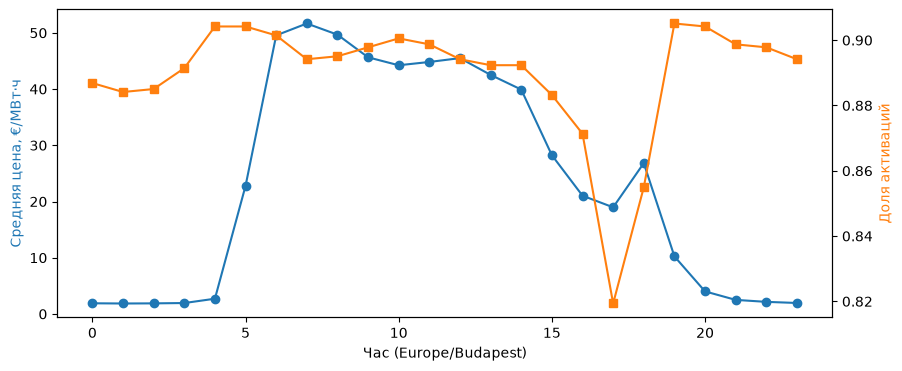

In [52]:
df["hour"] = df.index.hour
df["active"] = (df["target_vwap_up"] > 0).astype(int)
profile = df.groupby("hour").agg(cnt_actvation=("active", "mean"), mean_vwap_up=("target_vwap_up", "mean"))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("Час (Europe/Budapest)")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

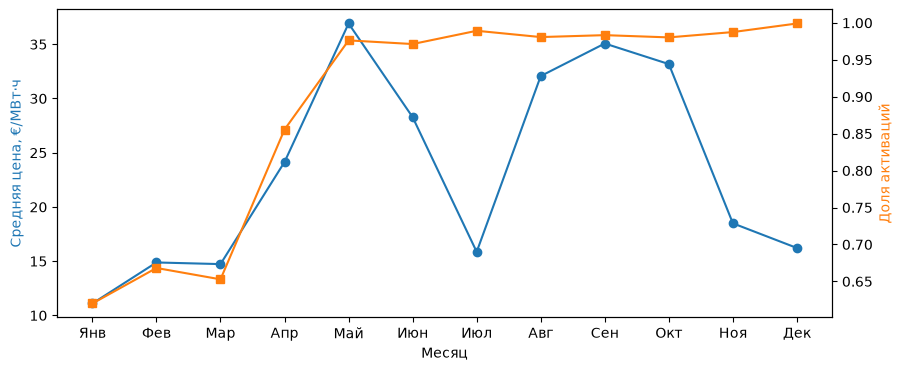

In [64]:

months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
          "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]

df["month"] = df.index.month
profile = df.groupby("month").agg(
    cnt_actvation=("active", "mean"),
    mean_vwap_up=("target_vwap_up", "mean"),
)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(months)

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

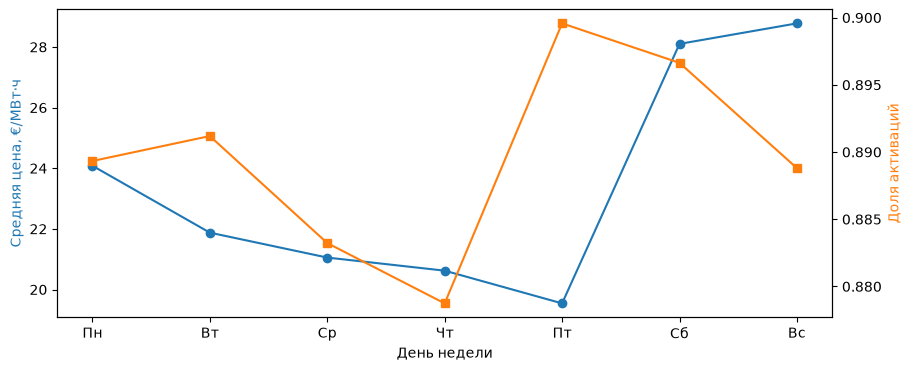

In [62]:
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

df["weekday"] = df.index.weekday
profile = df.groupby("weekday").agg(
    cnt_actvation=("active", "mean"),
    mean_vwap_up=("target_vwap_up", "mean"),
)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("День недели")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")
ax1.set_xticks(range(7))
ax1.set_xticklabels(days)

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

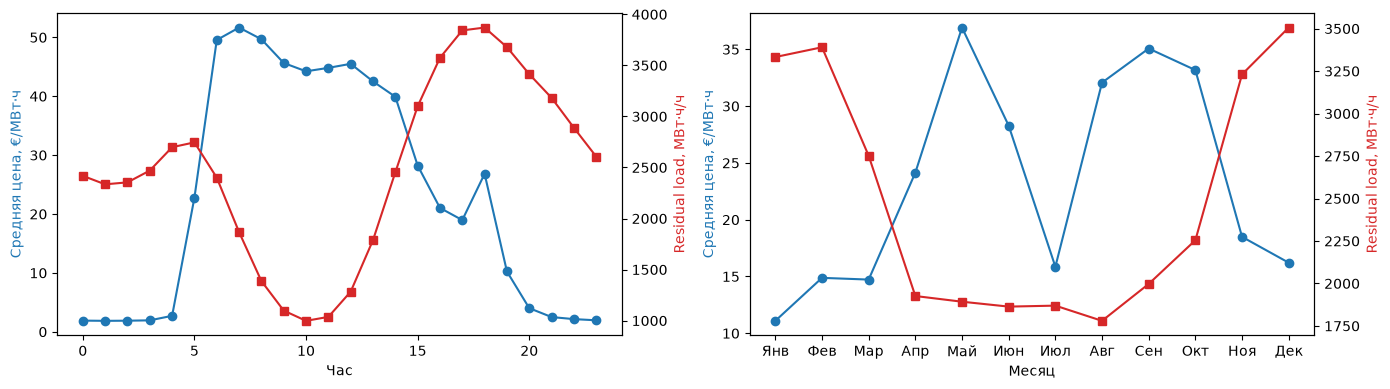

In [67]:
df["residual_load"] = df["consumption"] - df["wind"] - df["solar"] - df["nuclear"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# по часам: цена и residual load
rl_h = df.groupby("hour")["residual_load"].mean()
p_h = df.groupby("hour")["target_vwap_up"].mean()

axes[0].plot(p_h.index, p_h, color="C0", marker="o")
axes[0].set_ylabel("Средняя цена, €/МВт·ч", color="C0")
axes[0].set_xlabel("Час")
twin = axes[0].twinx()
twin.plot(rl_h.index, rl_h, color="C3", marker="s")
twin.set_ylabel("Residual load, МВт·ч/ч", color="C3")

# по месяцам
rl_m = df.groupby("month")["residual_load"].mean()
p_m = df.groupby("month")["target_vwap_up"].mean()

axes[1].plot(p_m.index, p_m, color="C0", marker="o")
axes[1].set_ylabel("Средняя цена, €/МВт·ч", color="C0")
axes[1].set_xlabel("Месяц")
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(months)
twin2 = axes[1].twinx()
twin2.plot(rl_m.index, rl_m, color="C3", marker="s")
twin2.set_ylabel("Residual load, МВт·ч/ч", color="C3")

plt.tight_layout()
plt.show()

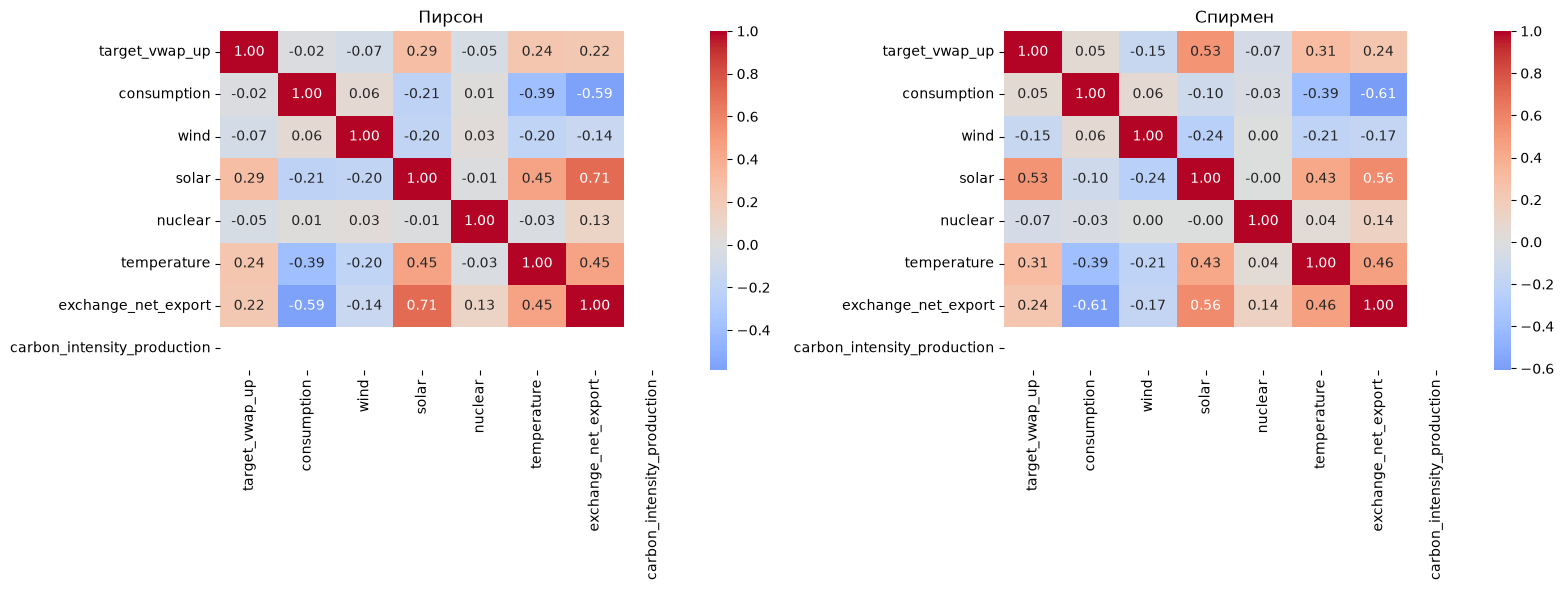

In [60]:
import seaborn as sns

cols = ["target_vwap_up", "consumption", "wind", "solar", "nuclear",
        "temperature", "exchange_net_export", "carbon_intensity_production"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[cols].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Пирсон")
sns.heatmap(df[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Спирмен")
plt.tight_layout()
plt.show()